# Gradient Boosting / Classifier

**Type:** Guided machine-learning practice notebook (course-based study).  
**Purpose:** Explore the dataset and the modeling/preprocessing operations illustrated in the code below.  
**Data in this folder:** `heart.csv`.  
**Methods referenced:** `DecisionTreeRegressor`, `GradientBoostingClassifier`.

> **Reproducibility note:** Run cells sequentially from this notebook’s folder. Outputs are historical study results, not independently validated benchmarks. The data files were supplied with the original archive; see `DATA_SOURCES.md` at the repository root for provenance checks.


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.ensemble import GradientBoostingClassifier

In [2]:
df = pd.read_csv("heart.csv")

In [3]:
df.head(10)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


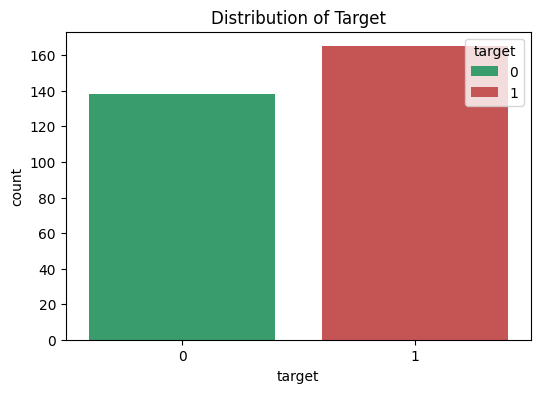

In [5]:
plt.figure(figsize = (6, 4))
sns.countplot(data = df, x = "target", hue = "target", palette = ["#29AC6D", "#D84242"])
plt.title("Distribution of Target")
plt.show()

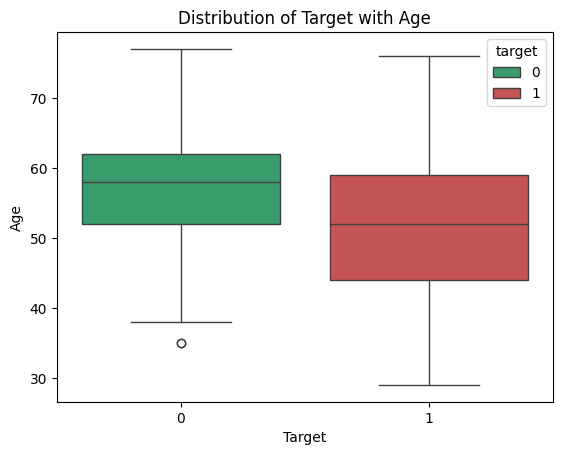

In [6]:
sns.boxplot(data = df, x = "target", y = "age", hue = "target", palette = ["#29AC6D", "#D84242"])
plt.title("Distribution of Target with Age")
plt.xlabel("Target")
plt.ylabel("Age")
plt.show()

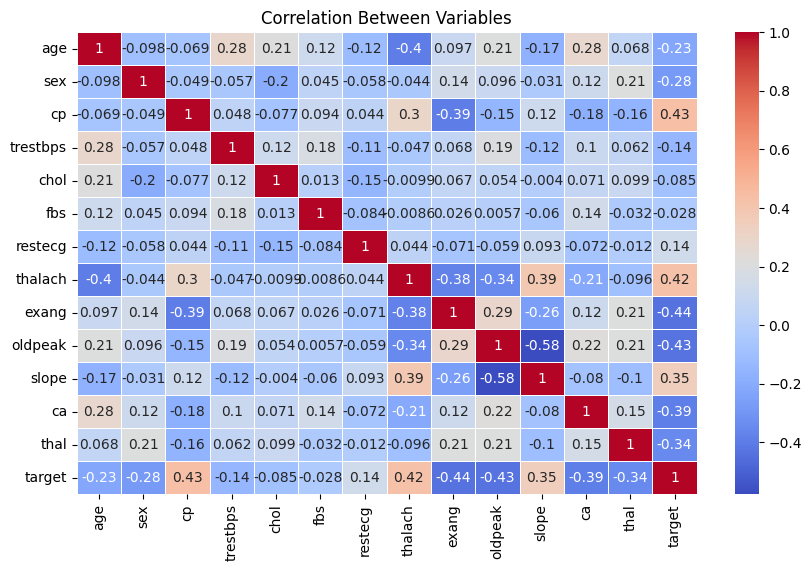

In [7]:
plt.figure(figsize = (10, 6))
sns.heatmap(data = df.corr(), annot = True, cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Between Variables")
plt.show()

In [8]:
X = df.drop("target", axis = 1)
y = df["target"]

In [9]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

In [10]:
gb = GradientBoostingClassifier()
gb.fit(X_train, y_train)

,loss,'log_loss'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [11]:
y_pred = gb.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.64      0.69      0.67        36
           1       0.79      0.75      0.77        55

    accuracy                           0.73        91
   macro avg       0.71      0.72      0.72        91
weighted avg       0.73      0.73      0.73        91

[[25 11]
 [14 41]]


In [12]:
parameters = {
        "loss" : ['log_loss', 'exponential'],
        "learning_rate" : [0.01, 0.05, 0.1],
        "n_estimators" : [100, 150, 180, 200],
        "max_depth" : [3,4,5],
        "subsample" : [0.8, 1.0]
}

In [13]:
grid = GridSearchCV(estimator = GradientBoostingClassifier(), param_grid = parameters, verbose = 1, n_jobs = -1)

In [14]:
grid.fit(X_train, y_train)

Fitting 5 folds for each of 144 candidates, totalling 720 fits


,estimator,GradientBoostingClassifier()
,param_grid,"{'learning_rate': [0.01, 0.05, ...], 'loss': ['log_loss', 'exponential'], 'max_depth': [3, 4, ...], 'n_estimators': [100, 150, ...], ...}"
,scoring,None
,n_jobs,-1
,refit,True
,cv,None
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,loss,'exponential'


In [15]:
grid.best_params_

{'learning_rate': 0.01,
 'loss': 'exponential',
 'max_depth': 3,
 'n_estimators': 200,
 'subsample': 0.8}

In [16]:
y_pred = grid.predict(X_test)
print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.69      0.67      0.68        36
           1       0.79      0.80      0.79        55

    accuracy                           0.75        91
   macro avg       0.74      0.73      0.73        91
weighted avg       0.75      0.75      0.75        91

[[24 12]
 [11 44]]
